# Tutorial: **δHBV 1.1p**

---

This notebook demonstrates training and forward simulation with the δHBV 1.1p model developed by [Yalan Song et al. (2025)](https://doi.org/10.22541/essoar.172304428.82707157/v2). A pre-trained model is provided for those who only wish to run the model forward.

For explanation of model structure, methodologies, data, and performance metrics, please refer to Song's publication [below](#publication). If you find this code is useful in your own work, please include the aforementioned citation.

**Note**: If you are new to the dMG framework, we suggest first looking at our [δHBV 1.0 tutorial](./../hydrology/example_dhbv.ipynb).

<br>

### Before Running:
- **Environment**: See [setup.md](./../../docs/setup.md) for ENV setup. dMG must be installed with dependencies + hydrodl2 to run this notebook.

- **Model**: Download pretrained δHBV 1.1p model weights from [AWS](https://mhpi-spatial.s3.us-east-2.amazonaws.com/mhpi-release/models/dhbv_1_1p_trained.zip). Then update the model config:

    - In [`./generic_deltamodel/example/conf/config_dhbv_1_1p.yaml`](./../conf/config_dhbv_1_1p.yaml), update *trained_model* with your path to the parent directory containing both trained model weights `dhbv_1_1p_ep50.pt` (or *Ep100*) **and** normalization file `normalization_statistics.json`.
    - **Note**: make sure this path includes the last closing forward slash: e.g., `./your/path/to/model/`.

- **Data**: Download the CAMELS data extraction from [AWS](https://mhpi-spatial.s3.us-east-2.amazonaws.com/mhpi-release/camels/camels_data.zip). Then, updated the data configs:

    - In [`./generic_deltamodel/example/conf/observations/camels_531.yaml`](./../conf/observations/camels_531.yaml) and [`camels_671.yaml`](./../conf/observations/camels_671.yaml), update...
        1. *data_path* with `camels_dataset` path,
        2. *gage_info* with `gage_ids.npy` path,
        3. *subset_path* with `531_subset.txt` path (camels_531 only).

    - The full 671-basin or 531-basin CAMELS datasets can be selected by setting `observations: camels_671` or `camels_531` in the model config, respectively.

- **Hardware**: The NNs used in this model require CUDA support only available with Nvidia GPUs. For those without access, T4 GPUs can be used when running this notebook with dMG on [Google Colab](https://colab.research.google.com/).

<br>

### Publication:

*Yalan Song, Kamlesh Sawadekar, Jonathan M Frame, Ming Pan, Martyn Clark, Wouter J M Knoben, Andrew W Wood, Trupesh Patel, Chaopeng Shen. "Physics-informed, Differentiable Hydrologic  Models for Capturing Unseen Extreme Events." ESS Open Archive (2025). https://doi.org/10.22541/essoar.172304428.82707157/v2.*

<br>

### Issues:
For questions, concerns, bugs, etc., please reach out by posting an [issue](https://github.com/mhpi/generic_deltamodel/issues).

---


## 1. Forward δHBV 1.1p Simulation Mode (no output metrics saved)

After completing training or you have pretrianed models saved, forward δHBV 1.1p with the code block below.

Note:
- The settings defined in the config `./generic_deltamodel/example/conf/config_dhbv_1_1p.yaml` are set to replicate benchmark performance on 531 CAMELS basins.
- The first year (`warm_up` in the config, default is 365 days) of the inference period is used for initializing HBV's internal states (water storages) and is, therefore, excluded from the model's prediction output.

### 1.1 Simulation Settings Demonstration

In [4]:
import sys
sys.path.append('../../') 
from src.dmg import ModelHandler 
from src.dmg.core.utils import import_data_loader, print_config, print_dataset_info, set_randomseed
from tempfunctions import *
from example import load_config 
#------------------------------------------#
# Define model settings here.
from tempfunctions import get_config_path

MODEL_TYPE = "d3"   # change only this: "d3", "d2", or "static"
CONFIG_PATH = get_config_path(MODEL_TYPE)
#------------------------------------------#

# 1. Load configuration dictionary of model parameters and options.
config = load_config(CONFIG_PATH)
config['mode'] = 'sim'

print_config(config)
# print("Config Keys:", config.keys())
# print("config['multimodel_type']", config['multimodel_type'])
# Set random seed for reproducibility.
set_randomseed(config['seed'])

# 2. Initialize the differentiable HBV 1.1p model (LSTM + HBV 1.1p).
model = ModelHandler(config, verbose=True) # model key is ['Hbv_1_1p'] 
nn_model = model.model_dict["Hbv_1_1p"].nn_model

# 3. Load and initialize a dataset dictionary of NN and HBV model inputs.
data_loader_cls = import_data_loader(config['data_loader'])
data_loader = data_loader_cls(config, test_split=False, overwrite=False)
print_dataset_info(data_loader.dataset)    


Current Configuration
  Experiment Mode:    sim                 
  Model 1:            Hbv_1_1p            
  Dynamic Params:     ['parBETA', 'parK0', 'parBETAET']

Data Loader
  Data Source:        camels_531          
  Simulation Range :  2009/10/01          2013/09/30          

Experiment Parameters
  Train Epochs:       100                 Batch Size:         100                 
  Start Epoch:        0                   Save Epoch:         5                   
  Loss Fn:            NseBatchLoss        
  Optimizer:          Adadelta            LR Scheduler:       None                

Machine
  Device:             cuda:0              
  Dtype:              torch.float32       


Dataset Inputs
Dataset key    Shape               Description
------------------------------------------------------------
x_phy          (1461, 531, 3)       # [time, basin, forcing_features]
c_phy          (531, 0)             # [basin, attr_features] (no physical attributes here)
x_nn           (1461

### 2 GEFS Simulation with 10 Lead Days (select from 1 or multiple basins), data saved to npz files

In [13]:
import importlib
import numpy as np
import json
import tempfunctions
importlib.reload(tempfunctions)

import os
import sys
import traceback
from datetime import datetime
from contextlib import redirect_stdout, redirect_stderr

# ========================================================
# 1. SETTINGS
# ========================================================

TEST2 = False  # True: 36 basins; False: single basin
SKIP = True

gage_ids = np.load(config["observations"]["gage_info"], allow_pickle=True)
subset_file = config["observations"]["subset_path"]
GAGE_NAME_PATH = "./predownloaded/camels_name.txt"

START_DATE = "2012-01-01"
END_DATE   = "2012-12-31"
PRE        = "scalar"
WINDOW     = 30
POST       = True
device     = torch.device("cuda" if torch.cuda.is_available() else "cpu") 

# ========================================================
# 2. SELECT BASINS
# ========================================================
with open(subset_file, "r") as f:
    content = f.read().strip()
gage_ids_subset = json.loads(content) if content.startswith("[") else np.loadtxt(subset_file, dtype=int).tolist() 

if config["observations"]["name"] == "camels_671":
    loader_basin_pool = [int(b) for b in gage_ids]

elif config["observations"]["name"] == "camels_531":
    loader_basin_pool = [int(b) for b in gage_ids_subset]

# Basins to process
if TEST2:
    target_basins = [int(b) for b in selectbasins()]
else:
    GAGE_ID = int("01487000")
    target_basins = [GAGE_ID]

# Check basin IDs before running
for gage_id in target_basins:
    if gage_id not in loader_basin_pool:
        raise ValueError(
            f"Basin {gage_id:08d} not found in data_loader"
        )

print("Requested # of basins:", len(target_basins))

# ========================================================
# 3. LOG SETTINGS
# ========================================================

LOG_DIR = os.path.join(
    config["sim_dir"],
    "GEFS_1year_forecasts",
    f"{START_DATE}_{END_DATE}_pre-{PRE}_w{WINDOW}_post-{POST}",
    "logs"
)

os.makedirs(LOG_DIR, exist_ok=True)

LOG_FILE = os.path.join(
    LOG_DIR,
    f"GEFS_{'all_basins' if TEST2 else 'single_basin'}_"
    f"{datetime.now():%Y%m%d_%H%M%S}.log"
)

print("Log file:", LOG_FILE)

# ========================================================
# 4. RUN FORECASTS
# ========================================================

gefs_results = {}
failed_basins = {}

with open(LOG_FILE, "w", buffering=1) as log_file:

    with redirect_stdout(log_file), redirect_stderr(log_file):

        print("=" * 60, flush=True)
        print("GEFS FORECAST EXPERIMENT", flush=True)
        print("=" * 60, flush=True)

        print("Start time:", datetime.now(), flush=True)
        print("Number of basins:", len(target_basins), flush=True)
        print("Start date:", START_DATE, flush=True)
        print("End date:", END_DATE, flush=True)
        print("Preprocessing:", PRE, flush=True)
        print("Window:", WINDOW, flush=True)
        print("Postprocessing:", POST, flush=True)

        for i, gage_id in enumerate(target_basins, start=1):

            print(
                f"\n{'=' * 60}\n"
                f"Processing basin {i}/{len(target_basins)}: "
                f"{gage_id:08d}\n"
                f"{'=' * 60}",
                flush=True
            )

            try: # save data to npz files
                result = tempfunctions.run_gefs_one_year(
                    GAGE_ID=gage_id,
                    model=model,
                    data_loader=data_loader,
                    config=config,

                    # Important: full data-loader basin ordering
                    basin_pool=loader_basin_pool,

                    startid_endid=tempfunctions.startid_endid,
                    run_segment=tempfunctions.run_segment,
                    run_warm_forecasts_restart=tempfunctions.run_warm_forecasts_restart,
                    post_processing=tempfunctions.post_processing,

                    START_DATE=START_DATE,
                    END_DATE=END_DATE,

                    FORECAST=10,
                    N_ENSEMBLES=5,
                    WARMUP=365,

                    WINDOW=WINDOW,
                    PRE=PRE,
                    POST=POST,

                    device=device,
                    skip_existing=SKIP,
                )

                gefs_results[gage_id] = result

                if result["n_failed"] > 0:
                    failed_basins[gage_id] = result["failed_dates"]

                print(
                    f"Completed basin {gage_id:08d} | "
                    f"Saved: {result['n_saved']} | "
                    f"Skipped: {result['n_skipped']} | "
                    f"Failed: {result['n_failed']}",
                    flush=True
                )

            except Exception as e:

                failed_basins[gage_id] = str(e)

                print(
                    f"FAILED BASIN {gage_id:08d}: {e}",
                    flush=True
                )

                traceback.print_exc()

        # Print final summary
        tempfunctions.print_gefs_summary(
            target_basins=target_basins,
            gefs_results=gefs_results,
            failed_basins=failed_basins
        )

# ========================================================
# 6. FINISHED
# ========================================================

print("\nForecast processing finished.")
print("Requested basins:", len(target_basins))
print("Completed basins:", len(gefs_results))
print("Basins with failures:", len(failed_basins)) 

Requested # of basins: 1
Log file: ./output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/logs/GEFS_single_basin_20261030_214627.log

Forecast processing finished.
Requested basins: 1
Completed basins: 1
Basins with failures: 1


### 3 Plot with CRPSS

Mode: single
Reference: observed
Requested basins: 1
[1/1] 01487000: 362 forecasts


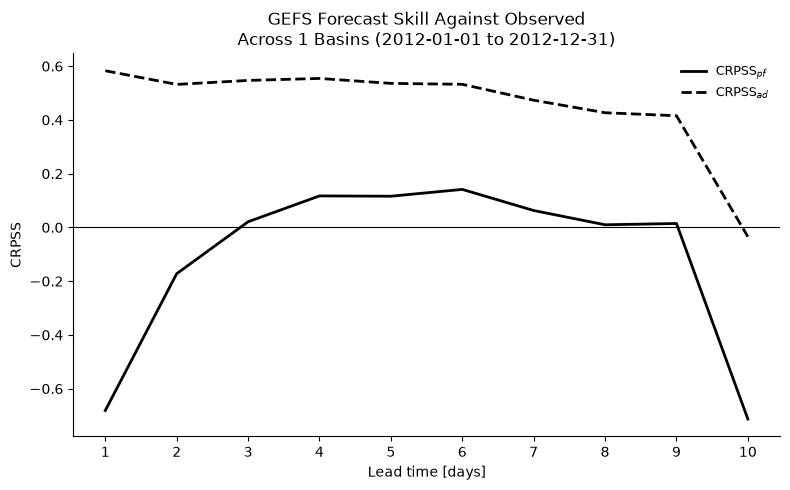


Evaluated: 1
Failed: 0
Figure: ./output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/CRPSS_observed_single/CRPSS_01487000_observed_2012.png
CSV: ./output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/CRPSS_observed_single/CRPSS_single_observed_2012.csv
Figure: ./output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/CRPSS_observed_single/CRPSS_01487000_observed_2012.png
CSV: ./output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/CRPSS_observed_single/CRPSS_single_observed_2012.csv
Failed basins: 0


In [15]:
import importlib
import tempfunctions

importlib.reload(tempfunctions)

# ========================================================
# 1. SELECT EVALUATION BASINS
# ========================================================

MODE = "single"  # "single" or "multiple"

if MODE == "single":
    eval_basins = [int(GAGE_ID)]
else:
    eval_basins = [int(b) for b in selectbasins()]

# ========================================================
# 2. LOAD OBSERVATIONS (NO CALIBRATION)
# ========================================================

basin_results = tempfunctions.build_observed_basin_results(
    data_loader=data_loader,
    config=config,
    loader_basin_pool=loader_basin_pool,
    selected_basins=eval_basins,
    WARMUP=365,
)

# ========================================================
# 3. CALCULATE CRPSS FROM SAVED NPZ
# ========================================================

crpss_results = tempfunctions.run_gefs_crpss(
    mode=MODE,
    config=config,
    basin_results=basin_results,
    basin_pool=eval_basins,
    GAGE_ID=eval_basins[0] if MODE == "single" else None,

    START_DATE=START_DATE,
    END_DATE=END_DATE,
    PRE=PRE,
    WINDOW=WINDOW,
    POST=POST,

    YEAR=2012,
    N_LEADS=10,
    N_ENSEMBLES=5,
    LEAD1_OFFSET=0,
    MIN_VALID_CASES=30,
    REFERENCE="observed",
    CLIMATOLOGY_YEARS=None,
    show_plot=True,
)

# display(crpss_results["summary_df"])

print("Figure:", crpss_results["figure_path"])
print("CSV:", crpss_results["csv_path"])
print("Failed basins:", len(crpss_results["failed_basins"]))

In [16]:
import os, glob
import numpy as np
import pandas as pd

bid = f"{int(GAGE_ID):08d}"

folder = os.path.join(
    config["sim_dir"],
    "GEFS_1year_forecasts",
    f"{START_DATE}_{END_DATE}_pre-{PRE}_w{WINDOW}_post-{POST}",
    bid
)

ref = basin_results[bid]
obs = pd.Series(
    np.asarray(ref["obs"], dtype=float),
    index=pd.to_datetime(ref["dates"]).normalize()
)

def exact_crps(ensemble, observation):
    x = np.asarray(ensemble, dtype=float)
    if not np.isfinite(observation) or not np.all(np.isfinite(x)):
        return np.nan
    return (np.mean(np.abs(x - observation))
            - 0.5 * np.mean(np.abs(x[:, None] - x[None, :])))

rows = []

for path in sorted(glob.glob(os.path.join(folder, "forecast_*.npz"))):
    with np.load(path) as data:
        fc = data["forecast"]
        init = pd.Timestamp(str(data["init_date"].item()))

    row = {"init_date": init}

    for lead in [9, 10]:
        y = obs.get(init + pd.Timedelta(days=lead - 1), np.nan)
        x = fc[:, lead - 1]

        row[f"obs_{lead}"] = y
        row[f"fc_mean_{lead}"] = np.mean(x)
        row[f"fc_max_{lead}"] = np.max(x)
        row[f"crps_{lead}"] = exact_crps(x, y)

    rows.append(row)

d = pd.DataFrame(rows).dropna()
d["increase"] = d["crps_10"] - d["crps_9"]

print("Number of dates:", len(d))
print("\nMean CRPS:")
print(d[["crps_9", "crps_10"]].mean())

print("\nMedian CRPS:")
print(d[["crps_9", "crps_10"]].median())

print("\nLargest Day 10 CRPS increases:")
display(d.nlargest(15, "increase").round(4))

print("\nContribution of 5 worst dates to net increase:")
print(
    d.nlargest(5, "increase")["increase"].sum()
    / d["increase"].sum()
)

Number of dates: 362

Mean CRPS:
crps_9     0.706203
crps_10    1.249892
dtype: float64

Median CRPS:
crps_9     0.259710
crps_10    0.266797
dtype: float64

Largest Day 10 CRPS increases:


/tmp/ipykernel_530582/3739053807.py:58: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(d.nlargest(15, "increase").round(4))


,init_date,obs_9,fc_mean_9,fc_max_9,crps_9,obs_10,fc_mean_10,fc_max_10,crps_10,increase
315,2012-11-14,0.6786,4.8962,22.078501,0.9503,0.6534,569.834229,2837.861084,114.5756,113.6253
306,2012-11-05,0.8964,13.5371,34.094501,5.6142,0.9131,256.079407,1191.611450,63.2272,57.6129
291,2012-10-21,3.1667,0.1622,0.172900,3.0000,31.6670,0.160200,0.176800,31.5007,28.5007
325,2012-11-24,0.5613,15.8823,75.693497,3.3184,0.5529,45.986900,136.241104,16.5857,13.2673
349,2012-12-18,1.7509,0.5887,0.789800,1.1004,7.5984,0.834500,1.433600,6.5702,5.4698
313,2012-11-12,0.7205,2.4994,7.059700,0.7853,0.7121,24.341400,111.987900,5.6260,4.8407
51,2012-02-21,1.2566,0.8115,1.650600,0.4041,5.1522,0.807700,1.635200,4.1504,3.7463
290,2012-10-20,0.2094,0.3211,1.023900,0.0722,3.1667,0.285700,0.793800,2.7736,2.7014
321,2012-11-20,0.6367,1.4059,3.765700,0.2347,0.6032,7.696300,25.292200,2.3548,2.1201
0,2012-01-01,1.1393,2.7369,9.503000,0.7533,1.1561,5.923200,12.126000,2.8302,2.0768



Contribution of 5 worst dates to net increase:
1.110056455933679



========== LEAD 3 ==========


,basin_id,CRPSS_pf,CRPSS_ad,CRPS_forecast,CRPS_ref_pf,CRPS_ref_ad
282,09508300,-10877.011799,-1129.978590,327.230151,0.030082,0.289334
322,14306500,-9433.627786,-3023.868229,4220.788619,0.447372,1.395363
182,06919500,-7002.487539,-363.416118,1.745656,0.000249,0.004790
272,09510200,-551.060870,-110.067728,9.450774,0.017119,0.085090
302,10234500,-501.355910,-35.693057,16.112744,0.032074,0.439122
172,06623800,-235.310438,-13.477956,2.370384,0.010031,0.163724
312,14301000,-197.536046,-38.456387,64.991903,0.327356,1.647183
222,08195000,-55.120219,-55.147857,2.430371,0.043307,0.043285



========== LEAD 9 ==========


,basin_id,CRPSS_pf,CRPSS_ad,CRPS_forecast,CRPS_ref_pf,CRPS_ref_ad
278,09510200,-188939.165564,-45728.547787,3891.135907,0.020595,0.085090
188,06919500,-33602.332965,-3102.118154,14.864808,0.000442,0.004790
288,09508300,-305.754324,-53.192080,15.679592,0.051114,0.289334
308,10234500,-225.953701,-28.534497,12.969260,0.057145,0.439122
178,06623800,-122.258700,-6.832890,1.282429,0.010404,0.163724
248,08378500,-87.646614,-50.673709,10.399987,0.117320,0.201263
328,14306500,-62.240058,-32.272183,46.426767,0.734135,1.395363
228,08195000,-27.918204,-48.333135,2.135395,0.073843,0.043285



========== LEAD 10 ==========


,basin_id,CRPSS_pf,CRPSS_ad,CRPS_forecast,CRPS_ref_pf,CRPS_ref_ad
279,09510200,-38486.172085,-9360.483129,796.570377,0.020697,0.085090
189,06919500,-10191.206762,-1010.052552,4.843226,0.000475,0.004790
239,08269000,-381.799905,-186.973234,24.928648,0.065122,0.132618
309,10234500,-355.209133,-48.439238,21.709878,0.060947,0.439122
289,09508300,-124.116642,-21.543415,6.522568,0.052132,0.289334
179,06623800,-110.529496,-6.530078,1.232852,0.011054,0.163724
329,14306500,-33.173651,-17.098006,25.253284,0.738969,1.395363
249,08378500,-30.607251,-18.085178,3.841133,0.121527,0.201263


,mean_pf,median_pf,positive_pf,mean_ad,median_ad,positive_ad,n_basins
lead_time,,,,,,,
1,-392.231,-7.816,0,-23.851,-0.216,12,35
2,-365.609,-5.580,0,-36.575,-0.385,12,35
3,-828.522,-4.302,3,-137.895,-0.389,11,35
4,-369.840,-5.763,3,-71.710,-0.388,11,35
5,-386.610,-5.955,4,-108.139,-0.862,10,35
6,-203.644,-4.733,4,-43.076,-0.676,10,35
7,-153.863,-3.650,4,-22.601,-0.447,12,35
8,-188.779,-4.193,6,-24.481,-0.436,12,35
9,-6385.207,-4.894,6,-1403.258,-0.801,11,35


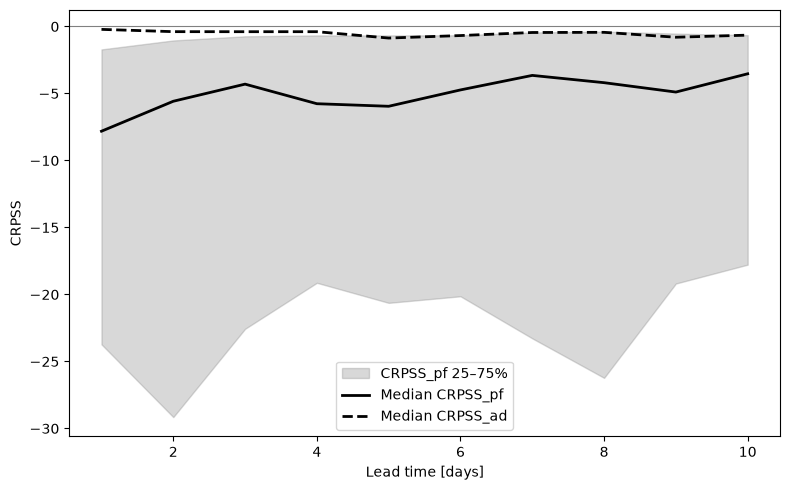

In [11]:
import pandas as pd

df = crpss_results["results_df"].copy()
df["basin_id"] = df["basin_id"].astype(str).str.zfill(8)

for lead in [3, 9, 10]:
    print(f"\n========== LEAD {lead} ==========")

    display(
        df[df["lead_time"] == lead]
        .nsmallest(8, "CRPSS_pf")
        [[
            "basin_id",
            "CRPSS_pf",
            "CRPSS_ad",
            "CRPS_forecast",
            "CRPS_ref_pf",
            "CRPS_ref_ad",
        ]]
    )

# Compare mean, median, and number of positive basins
summary = df.groupby("lead_time").agg(
    mean_pf=("CRPSS_pf", "mean"),
    median_pf=("CRPSS_pf", "median"),
    positive_pf=("CRPSS_pf", lambda x: (x > 0).sum()),
    mean_ad=("CRPSS_ad", "mean"),
    median_ad=("CRPSS_ad", "median"),
    positive_ad=("CRPSS_ad", lambda x: (x > 0).sum()),
    n_basins=("CRPSS_pf", "count"),
)

display(summary.round(3))
import matplotlib.pyplot as plt

stats = df.groupby("lead_time").agg(
    pf_median=("CRPSS_pf", "median"),
    pf_q25=("CRPSS_pf", lambda x: x.quantile(0.25)),
    pf_q75=("CRPSS_pf", lambda x: x.quantile(0.75)),
    ad_median=("CRPSS_ad", "median"),
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.fill_between(
    stats.index,
    stats["pf_q25"],
    stats["pf_q75"],
    color="gray",
    alpha=0.3,
    label="CRPSS_pf 25–75%"
)

ax.plot(stats.index, stats["pf_median"],
        "k-", lw=2, label="Median CRPSS_pf")

ax.plot(stats.index, stats["ad_median"],
        "k--", lw=2, label="Median CRPSS_ad")

ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("Lead time [days]")
ax.set_ylabel("CRPSS")
ax.legend()
plt.tight_layout()
plt.show()

Saved: ./output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/Evaluation_plots/01487000/GEFS_NS.png


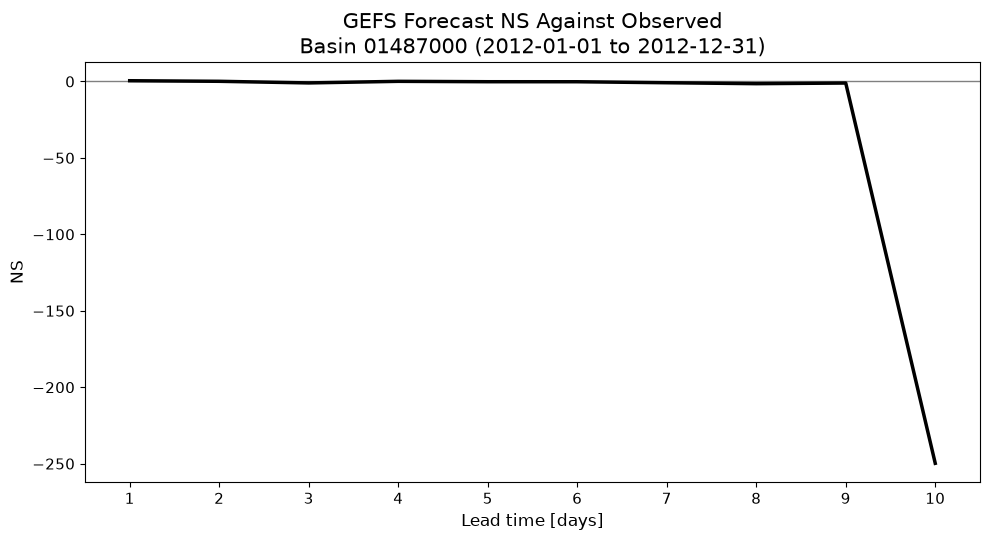

Saved: ./output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/Evaluation_plots/01487000/GEFS_Pbias_(pct).png


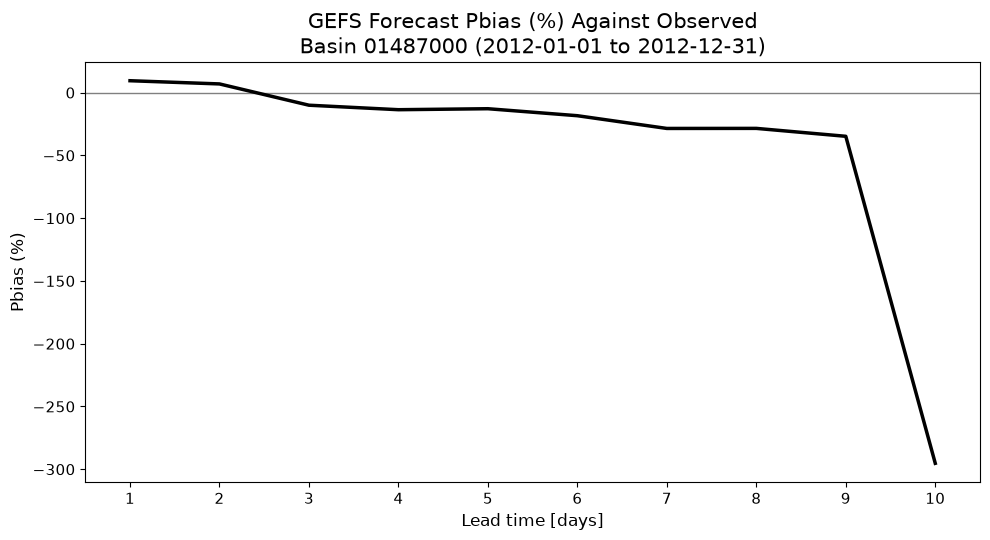

Saved: ./output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/Evaluation_plots/01487000/GEFS_CV.png


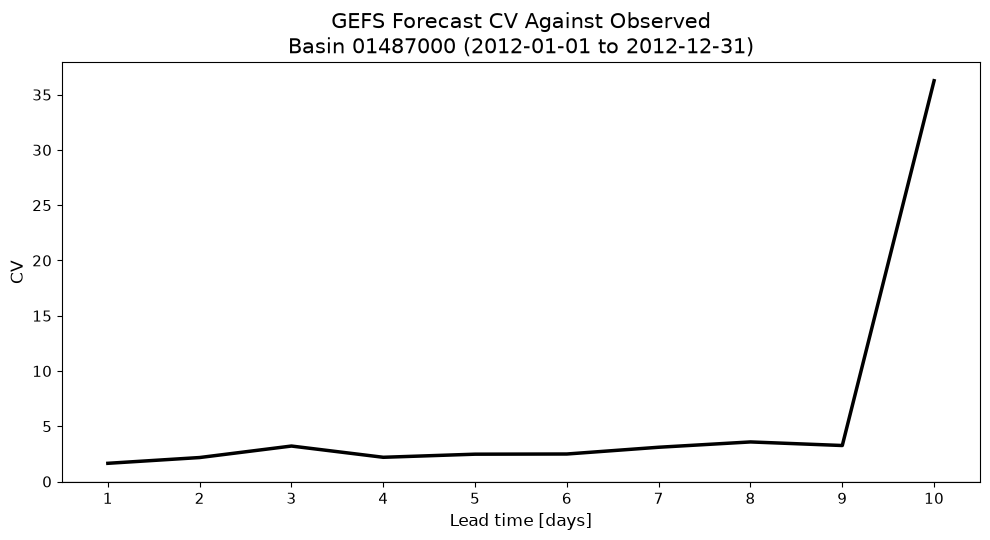

In [5]:
import os
import importlib
import tempfunctions

importlib.reload(tempfunctions)

# ========================================================
# STEP 1: LOAD SAVED GEFS FORECASTS
# ========================================================

ensemble_mean, target_flow = tempfunctions._load_gefs_metric_data(
    GAGE_ID=GAGE_ID,
    config=config,
    basin_results=basin_results,
    START_DATE=START_DATE,
    END_DATE=END_DATE,
    PRE=PRE,
    WINDOW=WINDOW,
    POST=POST,
    N_LEADS=10,
    N_ENSEMBLES=5,
    LEAD1_OFFSET=0,
    REFERENCE="observed",
)

# ========================================================
# STEP 2: CALCULATE METRICS
# ========================================================

ns = tempfunctions.calculate_gefs_ns(
    ensemble_mean, target_flow
)

pbias = tempfunctions.calculate_gefs_pbias(
    ensemble_mean, target_flow
)

cv = tempfunctions.calculate_gefs_cv(
    ensemble_mean, target_flow
)

# ========================================================
# STEP 3: OUTPUT DIRECTORY
# ========================================================

SAVE_ROOT = os.path.join(
    config["sim_dir"],
    "GEFS_1year_forecasts",
    f"{START_DATE}_{END_DATE}_pre-{PRE}_w{WINDOW}_post-{POST}"
)

PLOT_DIR = os.path.join(
    SAVE_ROOT,
    "Evaluation_plots",
    f"{int(GAGE_ID):08d}"
)

# ========================================================
# STEP 4: PLOT METRICS (CRPSS STYLE)
# ========================================================

for values, metric_name in [
    (ns, "NS"),
    (pbias, "Pbias (%)"),
    (cv, "CV"),
]:
    tempfunctions.plot_gefs_metric(
        values=values,
        metric_name=metric_name,
        save_dir=PLOT_DIR,
        START_DATE=START_DATE,
        END_DATE=END_DATE,
        basin_id=GAGE_ID,
    )